# Гибридная система рекомендаций книг (goodbooks-10k)

Лабораторный журнал решения: вызовы функций пакета `recsys` (`src/recsys`), промежуточные таблицы и графики по этапам. Постановка, обоснования и итоговые выводы — в `README.md`. Графики, используемые в README, сохраняются в `reports/figures/`.


## Этап 0. Подготовка: загрузка данных и проверка переноса моделей


### 0.1. Загрузка и валидация данных


In [1]:
import pandas as pd

from recsys import config, data, evaluation, split
from recsys.models import ContentBased, ItemCF, Popularity, PureSVD

pd.set_option("display.float_format", "{:.4f}".format)

dataset = data.load_all()
pd.Series(data.validate(dataset), name="value").to_frame()

,value
n_ratings,5976479
n_users,53424
n_books,10000
n_tags,34252
n_book_tags,999912
book_tags_duplicate_pairs,8
book_tags_nonpositive_count,6
books_missing_original_title,585


Проверка целостности данных завершается без критических нарушений: 8 дублирующихся пар (book_id, tag_name) и 6 записей с неположительным count в book_tags, 585 книг без original_title — некритические особенности, учитываемые при очистке тегов и построении текстовых профилей. Структура датасета (5 976 479 оценок, 53 424 пользователя, 10 000 книг) совпадает с ожидаемой по домашнему заданию.


### 0.2. Split train_inner / valid


In [2]:
outer = split.temporal_split(dataset.ratings)
inner = split.temporal_split(outer.train)
train_inner, valid = inner.train, inner.test
book_tags = data.clean_book_tags(dataset)
pd.Series({"train_inner": len(train_inner), "valid": len(valid)}, name="n_ratings")

train_inner    3824978
valid           956230
Name: n_ratings, dtype: int64

Train_inner и valid получены повторным применением per-user temporal split к обучающей части outer-разбиения, без обращения к отложенной test-выборке.


### 0.3. Smoke-проверка: nDCG@10 перенесённых моделей на valid


In [3]:
eval_set = evaluation.build_eval_set(train_inner, valid)

models = {
    "Popularity (weighted)": Popularity("weighted", config.POPULARITY_WR_M),
    "Content-Based": ContentBased(dataset.books, book_tags),
    "Item-based CF": ItemCF(),
    "PureSVD": PureSVD(config.PURE_SVD_N_FACTORS),
}
for model in models.values():
    model.fit(train_inner)

smoke_table = evaluation.compare(list(models.values()), eval_set, ks=(10,)).xs(10, level="k")
smoke_table[["ndcg"]]

,ndcg
model,
"Popularity[weighted, m=100000]",0.0441
Content-Based[tags=all],0.0536
"Item-CF[adjusted_cosine, K=50, λ=50, similarity]",0.0968
PureSVD[k=200],0.0733


nDCG@10 на valid для перенесённых моделей совпадает с результатами домашнего задания с точностью до 1e-4: Popularity (weighted) 0.0441, Content-Based 0.0536, Item-based CF 0.0968, PureSVD 0.0733. Совпадение чисел подтверждает корректность переноса кода, конфигурации протокола оценки и реализации split без изменений.


## Этап 1. Расширенные признаки

Признаки пользователей, книг и пар «пользователь × книга» строятся по train_inner — выборке, на которой на этапах 2–3 подбираются веса гибрида по valid. Тематические категории определяются по тегам книг (метаданные без оценок) и не зависят от split.

### 1.1. Тематические категории книг

In [4]:
from recsys import features, plots

plots.set_style()
categories = features.book_categories(book_tags)
category_shares = pd.DataFrame(
    {
        "n_books": categories.value_counts(sort=False),
        "books": categories.value_counts(normalize=True, sort=False),
        "ratings": train_inner["book_id"].map(categories).value_counts(normalize=True, sort=False),
    }
).sort_values("books", ascending=False)
covered = (categories != config.CATEGORY_OTHER).mean()
print(f"Доля книг с категорией, отличной от other: {covered:.1%}")
category_shares

Доля книг с категорией, отличной от other: 100.0%


,n_books,books,ratings
fantasy,1751,0.1751,0.2021
mystery_thriller,1304,0.1304,0.1016
non_fiction,1026,0.1026,0.0661
romance,929,0.0929,0.0634
classics,686,0.0686,0.1596
children,678,0.0678,0.0776
science_fiction,620,0.0620,0.0793
historical_fiction,572,0.0572,0.0641
literary_fiction,552,0.0552,0.0519
young_adult,494,0.0494,0.0427


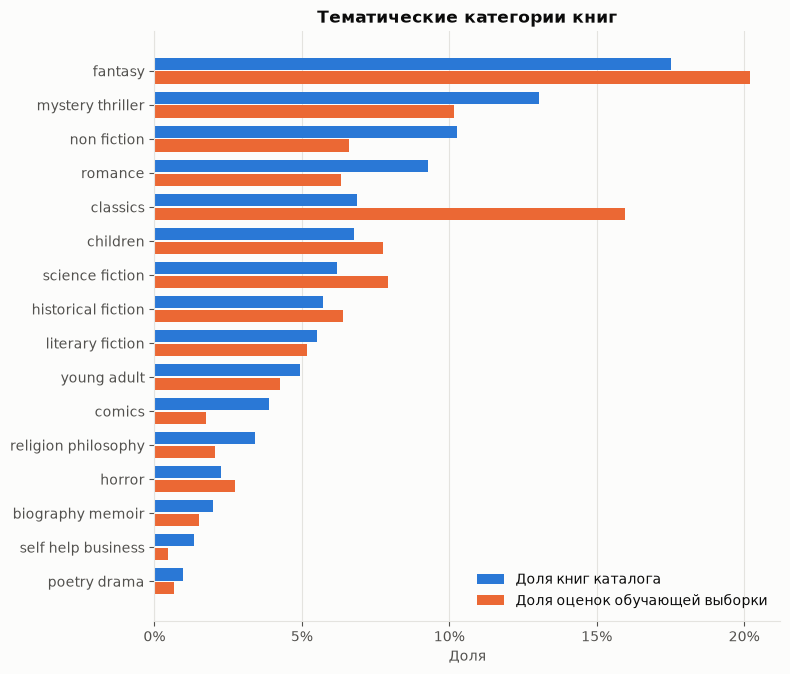

In [5]:
fig = plots.plot_category_shares(category_shares[category_shares["n_books"] > 0])
plots.save_figure(fig, "book_categories");

Категории восьми популярных книг каталога и суммы счётчиков тегов двух ведущих категорий:

In [6]:
tag_counts = features.category_tag_counts(book_tags)
example_books = [1, 2, 4, 13, 26, 35, 45, 50]
leading = tag_counts.loc[example_books].apply(
    lambda row: ", ".join(f"{c} {v:.0f}" for c, v in row.nlargest(2).items()), axis=1
)
dataset.books.set_index("book_id").loc[example_books, ["title"]].assign(
    category=categories.loc[example_books], leading_tag_counts=leading
)

,title,category,leading_tag_counts
book_id,,,
1,"The Hunger Games (The Hunger Games, #1)",science_fiction,"science_fiction 46294, young_adult 42896"
2,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy,"fantasy 68192, young_adult 22702"
4,To Kill a Mockingbird,classics,"classics 46913, historical_fiction 6097"
13,1984,science_fiction,"science_fiction 22485, classics 8853"
26,"The Da Vinci Code (Robert Langdon, #2)",mystery_thriller,"mystery_thriller 11139, literary_fiction 2259"
35,The Alchemist,religion_philosophy,"religion_philosophy 4934, classics 4096"
45,Life of Pi,literary_fiction,"literary_fiction 3843, fantasy 2548"
50,Where the Sidewalk Ends,children,"children 15001, poetry_drama 9503"


Все 10 000 книг получают одну из 16 тематических категорий: у каждой книги есть хотя бы один тег, совпадающий с шаблонами, поэтому категория other пуста и доля книг вне other составляет 100 %. Крупнейшие категории — fantasy (17.5 % книг), mystery_thriller (13.0 %) и non_fiction (10.3 %). Распределение оценок по категориям отличается от распределения книг: classics занимает 6.9 % каталога и 16.0 % оценок train_inner, fantasy — 17.5 % и 20.2 %, а у comics, religion_philosophy и self_help_business доля оценок в 1.7–2.9 раза ниже доли книг. У книг на стыке жанров категорию определяет группа тегов с наибольшей суммой счётчиков: The Hunger Games относится к science_fiction (46 294 против 42 896 у young_adult), Harry Potter and the Sorcerer's Stone — к fantasy.

### 1.2. Признаки книг

In [7]:
book_feats = features.book_features(train_inner, categories)
book_feats.describe().T

,count,mean,std,min,25%,50%,75%,max
n_ratings,10000.0000,382.4978,945.2179,1.0000,85.0000,144.0000,303.0000,18807.0000
log_n_ratings,10000.0000,5.1507,1.0980,0.6931,4.4543,4.9767,5.7170,9.8420
mean_rating,10000.0000,3.9165,0.2992,2.0421,3.7347,3.9355,4.1176,5.0000
bayes_rating,10000.0000,3.9242,0.2142,2.4013,3.7939,3.9368,4.0667,4.7258
std_rating,10000.0000,0.9274,0.1232,0.0000,0.8521,0.9233,0.9999,1.5947
low_share,10000.0000,0.0786,0.0590,0.0000,0.0389,0.0651,0.1042,0.7143


Число оценок книги в train_inner меняется от 1 до 18 807 при медиане 144, поэтому кроме числа оценок используется его логарифм. Сглаживание Bayesian average с m = 50 сжимает разброс средней оценки: стандартное отклонение уменьшается с 0.299 до 0.214, минимум поднимается с 2.04 до 2.40, максимум снижается с 5.00 до 4.73 — книги с единичными оценками больше не занимают края шкалы. Доля оценок 1–2 в среднем равна 7.9 %, у четверти книг она превышает 10.4 %.

### 1.3. Признаки пользователей

In [8]:
user_feats = features.user_features(train_inner, categories)
print(user_feats["user_type"].value_counts().to_dict())
user_feats.describe().T

{'active': 53424, 'new': 0}


,count,mean,std,min,25%,50%,75%,max
n_ratings,53424.0000,71.5966,16.6911,12.0000,62.0000,71.0000,82.0000,128.0000
mean_rating,53424.0000,3.9469,0.4679,1.0000,3.6400,3.9444,4.2614,5.0000
std_rating,53424.0000,0.8517,0.2281,0.0000,0.7186,0.8512,0.9923,1.9990
liked_share,53424.0000,0.6988,0.1863,0.0000,0.5769,0.7160,0.8429,1.0000
mainstream,53424.0000,6.9055,0.6478,4.0244,6.4783,6.9473,7.3718,8.8990
n_categories,53424.0000,9.1939,2.6893,1.0000,7.0000,10.0000,11.0000,16.0000


В train_inner у пользователей от 12 до 128 оценок (медиана 71), поэтому при пороге θ = 10 новых пользователей в реальных данных нет: тип new возникает только при симуляции cold start с усечением истории до 1, 3, 5 и 10 оценок на этапе 3. В среднем 69.9 % оценок пользователя равны 4 или 5, а профиль по категориям охватывает несколько тематик: медиана числа категорий в истории — 10 из 16. Мейнстримность (среднее log(1 + n) по прочитанным книгам) меняется от 4.02 до 8.90, то есть геометрическое среднее числа оценок прочитанных книг — от 55 до 7 300.

Пример профиля пользователя: агрегаты и пять категорий с наибольшей долей понравившихся книг; affinity — сглаженная доля.

In [9]:
profile = features.category_profile(train_inner, categories)
affinity = features.category_affinity(train_inner, categories)
example_user = int(eval_set.user_ids[0])
display(user_feats.loc[[example_user]])
pd.DataFrame(
    {"liked_share": profile.loc[example_user], "affinity": affinity[example_user - 1]}
).nlargest(5, "liked_share")

,n_ratings,mean_rating,std_rating,liked_share,mainstream,n_categories,user_type
user_id,,,,,,,
1,75,3.4933,0.9849,0.4533,7.8745,10,active


,liked_share,affinity
classics,0.3529,0.3079
literary_fiction,0.1471,0.1243
historical_fiction,0.1471,0.1288
children,0.0882,0.0870
science_fiction,0.0588,0.0637


Более трети понравившихся книг пользователя 1 (35.3 %) относится к classics. Сглаживание сдвигает эту долю к доле classics среди понравившихся оценок train_inner: affinity составляет 30.8 %.

### 1.4. Признаки взаимодействий

Признаки пар считаются по моделям, обученным на train_inner. Проверка на 2 000 пользователях выборки оценки: средние значения признаков для релевантных книг valid и для того же числа случайных книг, отсутствующих в train_inner и valid пользователя.

In [10]:
import time

import numpy as np

from recsys.models import FunkSVD

start = time.perf_counter()
funk_svd = FunkSVD().fit(train_inner)
print(f"Обучение FunkSVD на train_inner: {time.perf_counter() - start:.0f} с")

rng = np.random.default_rng(config.RANDOM_STATE)
sample = evaluation.subset(eval_set, rng.choice(eval_set.user_ids, 2_000, replace=False))
rows, cols = sample.relevant.nonzero()
pair_users = np.tile(sample.user_ids[rows], 2)
negatives = features.sample_unseen_books(
    sample.user_ids[rows], eval_set.seen + data.interaction_matrix(valid, binary=True)
)
pair_books = np.concatenate([cols + 1, negatives])

start = time.perf_counter()
pairs = features.interaction_features(
    pair_users, pair_books, models["Content-Based"], models["Item-based CF"], funk_svd,
    affinity, categories,
)  # fmt: skip
print(f"Признаки {len(pairs):,} пар: {time.perf_counter() - start:.1f} с".replace(",", " "))
pairs["pair"] = np.repeat(["релевантная (valid)", "случайная непрочитанная"], rows.size)
pairs.groupby("pair")[["content_sim", "item_cf_score", "category_affinity", "svd_rating"]].mean()

Обучение FunkSVD на train_inner: 49 с


Признаки 48 274 пар: 1.8 с


,content_sim,item_cf_score,category_affinity,svd_rating
pair,,,,
релевантная (valid),0.2392,0.1630,0.2024,4.0896
случайная непрочитанная,0.1022,0.0088,0.0916,3.9965


Все четыре признака пар в среднем выше для релевантных книг valid, чем для случайных непрочитанных: Item-CF-скор — в 18.5 раза (0.1630 против 0.0088), content_sim — в 2.3 раза (0.2392 против 0.1022), category_affinity — в 2.2 раза (0.2024 против 0.0916). Прогноз оценки FunkSVD различается меньше (4.09 против 4.00): он отражает прежде всего смещения пользователя и книги, а не вероятность того, что книга будет прочитана. Признаки 48 274 пар вычисляются примерно за 3 с, что позволяет на этапе 2 считать их на пуле кандидатов всех пользователей выборки оценки. Вклад признаков в качество рекомендаций оценивается на этапе 3 сравнением гибрида с компонентой affinity и без неё.

## Этап 2. Гибридная система: кандидаты, веса, балансировка

Гибрид собирается из моделей, обученных на train_inner (раздел 0.3 и FunkSVD из 1.4), и проверяется на valid; test на этом этапе не используется. Веса компонент — стартовые значения из `config.HYBRID_START_WEIGHTS`, их подбор выполняется на этапе 3.

### 2.1. Пул кандидатов

Каждый источник (Popularity, Content-Based, Item-based CF, PureSVD) даёт до 50 непрочитанных книг пользователя; списки объединяются без дубликатов с флагами источников. Recall@pool — доля релевантных книг valid, попавших в пул; `unique_share` — доля найденных релевантных книг, которые дал только этот источник.

In [11]:
from recsys import candidates, hybrid
from recsys.balancing import Quotas

component_models = {
    "popularity": models["Popularity (weighted)"],
    "content": models["Content-Based"],
    "item_cf": models["Item-based CF"],
    "pure_svd": models["PureSVD"],
    "funk_svd": funk_svd,
}
hybrid_model = hybrid.HybridRecommender(
    component_models, categories, weights=config.HYBRID_START_WEIGHTS
)
hybrid_model.fit(train_inner, fit_models=False)
scored = hybrid_model.prepare(eval_set.user_ids)
pool = scored.pool
print(f"Пул и скоры компонент для {pool.user_ids.size} пользователей: {scored.seconds:.0f} с")
display(pd.Series(pool.sizes, name="pool_size").describe().to_frame().T)
candidates.pool_metrics(pool, eval_set)

Пул и скоры компонент для 10000 пользователей: 14 с


,count,mean,std,min,25%,50%,75%,max
pool_size,10000.0000,150.5859,10.0282,96.0000,144.0000,151.0000,157.0000,188.0000


,candidates,recall,unique_share
source,,,
popularity,50.0000,0.0900,0.0958
content,49.9900,0.1248,0.1082
item_cf,49.9878,0.2110,0.1351
pure_svd,50.0000,0.1642,0.1569
pool,150.5859,0.3547,0.4961


Доли пар пула по сочетаниям источников:

In [12]:
pool.composition().head(8).to_frame()

,share
sources,
popularity,0.2322
content,0.2114
pure_svd,0.1838
item_cf,0.1033
popularity+item_cf,0.0781
item_cf+pure_svd,0.0619
content+item_cf+pure_svd,0.0408
content+pure_svd,0.0346


Пул содержит в среднем 150.6 кандидата на пользователя (от 96 до 188) при 200 возможных: 73 % пар пула предложены только одним источником. Recall@pool равен 0.355 — в 1.7 раза выше, чем у лучшего отдельного источника Item-based CF (0.211 на 50 кандидатах). Источники дополняют друг друга: 49.6 % найденных релевантных книг даёт только один источник, причём доля уникальных находок у PureSVD (15.7 %) выше, чем у Item-based CF (13.5 %), при меньшей полноте. Recall@pool ограничивает сверху полноту любой выдачи гибрида: в среднем 64.5 % релевантных книг пользователя в пул не попадают. Пул и скоры компонент для 10 000 пользователей вычисляются за 14 с.

### 2.2. Взвешенный гибрид по типам пользователей

Скор книги пула: score(u, i) = Σ_m w_m(type_u) · s̃_m(u, i), где s̃_m — скор компоненты, нормированный min-max внутри пула пользователя, type_u — new (не более 10 оценок в train) или active. Стартовые веса:

In [13]:
pd.DataFrame(config.HYBRID_START_WEIGHTS).rename_axis("component")

,active,new
component,,
popularity,0.0500,0.4000
content,0.1500,0.2000
item_cf,0.4000,0.1500
pure_svd,0.2000,0.0500
funk_svd,0.1000,0.0500
affinity,0.1000,0.1500


Рекомендации гибрида для всей выборки valid, проверка выдачи (K книг, без прочитанного, без повторов) и сравнение на K = 10 с отдельными моделями. Строка «Гибрид: только item_cf» — контроль нормализации и ранжирования пула: при единственной ненулевой компоненте гибрид должен воспроизводить Item-based CF.

In [14]:
start = time.perf_counter()
hybrid_recs = hybrid_model.recommend(eval_set.user_ids, 20, exclude=eval_set.seen)
hybrid_seconds = time.perf_counter() - start
print(f"Рекомендации гибрида для {eval_set.user_ids.size} пользователей: {hybrid_seconds:.0f} с")

top10 = hybrid_recs[:, :10]
seen_in_top = int(eval_set.seen[np.repeat(eval_set.user_ids, 10) - 1, top10.ravel() - 1].sum())
duplicates = sum(np.unique(row).size < row.size for row in top10)
print(f"Пустых позиций: {(top10 < 0).sum()}, прочитанных книг: {seen_in_top}")
print(f"Списков с повторами: {duplicates}")

single_models = {**models, "FunkSVD": funk_svd}
valid_recs = {
    name: model.recommend(eval_set.user_ids, 20, exclude=eval_set.seen)
    for name, model in single_models.items()
}
only_item_cf = hybrid_model.with_params(
    weights={"active": {"item_cf": 1.0}, "new": {"item_cf": 1.0}}
)
valid_recs["Гибрид: только item_cf"] = only_item_cf.rank(scored, 20)
valid_recs["Гибрид"] = hybrid_recs
columns = ["precision", "recall", "ndcg", "hit_rate", "coverage", "novelty"]
evaluation.compare_recommendations(valid_recs, eval_set).xs(10, level="k")[columns]

Рекомендации гибрида для 10000 пользователей: 15 с
Пустых позиций: 0, прочитанных книг: 0
Списков с повторами: 0


,precision,recall,ndcg,hit_rate,coverage,novelty
model,,,,,,
Popularity (weighted),0.0386,0.0323,0.0441,0.2038,0.0039,8.3973
Content-Based,0.0474,0.0411,0.0536,0.2943,0.4881,12.1374
Item-based CF,0.0842,0.0734,0.0968,0.4265,0.4086,10.8430
PureSVD,0.0646,0.0552,0.0733,0.3893,0.1963,11.1217
FunkSVD,0.0019,0.0017,0.0019,0.0151,0.0439,14.9290
Гибрид: только item_cf,0.0842,0.0734,0.0968,0.4265,0.4086,10.8429
Гибрид,0.0839,0.0725,0.0957,0.4342,0.4061,11.1059


Гибрид выдаёт по 20 книг всем 10 000 пользователям valid без пустых позиций, прочитанных книг и повторов; рекомендации формируются за 13 с. С единственной компонентой item_cf гибрид воспроизводит Item-based CF (nDCG@10 0.0968), что подтверждает корректность нормализации и ранжирования внутри пула. Со стартовыми весами nDCG@10 гибрида равен 0.0957 — на 1.1 % ниже, чем у Item-based CF. HitRate@10 при этом выше на 1.8 % (0.4342 против 0.4265), Coverage@10 близок (0.406 против 0.409), новизна больше (Novelty@10 11.11 против 10.84). Стартовые веса заданы без подбора: они подбираются по nDCG@10 на valid на этапе 3. FunkSVD как отдельная модель top-N непригоден (nDCG@10 0.0019, Novelty@10 14.93): прогноз оценки выводит в top-10 малоизвестные книги, поэтому в гибриде FunkSVD участвует только как компонента скора на пуле.

### 2.3. Балансировка разнообразия и релевантности

Жадное переранжирование пула: не более q книг одной категории в top-10 и не менее t книг вне head (1 000 самых популярных книг train_inner, 10 % каталога). Если состав пула не позволяет выполнить квоты, они ослабляются по очереди: сначала квота long tail, затем квота категорий; выбранные книги упорядочиваются по скору. Квоты действуют на весь список длины K, поэтому сбалансированные списки строятся для K = 10. `n_categories` — число различных категорий в top-10, `ild` — 1 − доля пар top-10 из одной категории, `tail_share` — доля позиций вне head.

In [15]:
balance_variants = {
    "Гибрид": hybrid_model,
    "Гибрид + квота категорий (q=3)": hybrid_model.with_params(quotas=Quotas(3, 0)),
    "Гибрид + квоты (q=3, t=3)": hybrid_model.with_params(quotas=Quotas(3, 3)),
}
balanced_recs = {name: model.rank(scored, 10) for name, model in balance_variants.items()}
balanced_recs["Item-based CF"] = valid_recs["Item-based CF"][:, :10]
category_codes = categories.cat.codes.to_numpy()
quality = evaluation.compare_recommendations(balanced_recs, eval_set, ks=(10,)).xs(10, level="k")
quality[["ndcg", "recall", "hit_rate", "coverage", "novelty"]].join(
    evaluation.diversity_metrics(balanced_recs, category_codes, hybrid_model.is_head)
)

,ndcg,recall,hit_rate,coverage,novelty,n_categories,ild,tail_share
model,,,,,,,,
Гибрид,0.0957,0.0725,0.4342,0.4061,11.1059,2.5431,0.4040,0.2739
Гибрид + квота категорий (q=3),0.0880,0.0651,0.4597,0.3904,10.7213,4.6484,0.8301,0.1951
"Гибрид + квоты (q=3, t=3)",0.0865,0.0633,0.4501,0.4477,11.1153,4.6431,0.8299,0.3156
Item-based CF,0.0968,0.0734,0.4265,0.4086,10.8430,3.3199,0.5263,0.2811


Стартовый гибрид концентрирует выдачу на любимых категориях пользователя: в top-10 в среднем 2.54 категории против 3.32 у Item-based CF, intra-list diversity — 0.404 против 0.526; компоненты content и affinity усиливают сходство с профилем. Квота q = 3 повышает число категорий до 4.65 и ILD до 0.830, а nDCG@10 снижается на 8.0 % (0.0957 → 0.0880). HitRate@10 при этом растёт на 5.9 % (0.4342 → 0.4597), а Recall@10 падает (0.0725 → 0.0651): разнообразный список чаще содержит хотя бы одну релевантную книгу, но в сумме находит меньше релевантных книг. Одна квота категорий снижает долю книг вне head с 0.274 до 0.195: место вытесненных книг любимой категории занимают популярные книги других категорий. Квота t = 3 возвращает долю long tail к 0.316 и повышает Coverage@10 на 10 % (0.406 → 0.448); nDCG@10 снижается ещё на 0.0015 (до 0.0865). Значения q и t уточняются на этапе 3.

### 2.4. Пример выдачи

Top-10 пользователя из раздела 1.3 без балансировки (источники кандидата, категория, нормированные скоры компонент) и с квотами q = 3, t = 3:

In [16]:
display(hybrid_model.explain(example_user, dataset.books).round(3))
balance_variants["Гибрид + квоты (q=3, t=3)"].explain(example_user, dataset.books)[
    ["book_id", "title", "category", "head", "sources", "score"]
].round(3)

,book_id,title,category,head,sources,popularity,content,item_cf,pure_svd,funk_svd,affinity,score
position,,,,,,,,,,,,
1,76,Sense and Sensibility,classics,True,content+item_cf+pure_svd,0.3300,0.7660,0.9420,0.4600,0.5180,1.0000,0.7520
2,14,Animal Farm,classics,True,content+item_cf,0.1690,0.7850,0.8360,0.2780,0.5980,1.0000,0.6760
3,225,East of Eden,classics,True,popularity+content+item_cf,0.4110,0.7130,0.8310,0.1700,0.7650,1.0000,0.6700
4,172,Anna Karenina,classics,True,content+item_cf+pure_svd,0.2990,0.8980,0.3910,1.0000,0.6050,1.0000,0.6660
5,485,The Brothers Karamazov,classics,True,content+item_cf+pure_svd,0.3340,0.8350,0.4900,0.5940,0.7110,1.0000,0.6280
6,265,A Tree Grows in Brooklyn,classics,True,popularity+item_cf,0.3820,0.6490,0.6610,0.3680,0.7200,1.0000,0.6260
7,28,Lord of the Flies,classics,True,content+item_cf,0.0290,0.9490,0.6880,0.2470,0.4170,1.0000,0.6100
8,1,"The Hunger Games (The Hunger Games, #1)",science_fiction,True,popularity+item_cf,0.8860,0.1010,1.0000,0.3290,0.5340,0.1950,0.5980
9,195,The Guernsey Literary and Potato Peel Pie Society,historical_fiction,True,item_cf+pure_svd,0.3460,0.2990,0.6200,0.8630,0.6360,0.4100,0.5870


,book_id,title,category,head,sources,score
position,,,,,,
1,76,Sense and Sensibility,classics,True,content+item_cf+pure_svd,0.7520
2,14,Animal Farm,classics,True,content+item_cf,0.6760
3,225,East of Eden,classics,True,popularity+content+item_cf,0.6700
4,1,"The Hunger Games (The Hunger Games, #1)",science_fiction,True,popularity+item_cf,0.5980
5,195,The Guernsey Literary and Potato Peel Pie Society,historical_fiction,True,item_cf+pure_svd,0.5870
6,25,Harry Potter and the Deathly Hallows (Harry Po...,fantasy,True,popularity+item_cf,0.5810
7,291,Cutting for Stone,historical_fiction,True,popularity+item_cf+pure_svd,0.5800
8,2,Harry Potter and the Sorcerer's Stone (Harry P...,fantasy,True,popularity+item_cf,0.5770
9,15,The Diary of a Young Girl,non_fiction,True,popularity+item_cf,0.5420


У пользователя 1 (classics — 35.3 % понравившихся книг) семь из десяти книг выдачи без балансировки относятся к classics: нормированная affinity к этой категории равна 1.0 и вместе с content поднимает книги одного жанра. Квота q = 3 заменяет четыре книги classics книгами historical_fiction, fantasy, non_fiction и biography_memoir — в выдаче шесть категорий вместо четырёх. Книг вне head в выдаче нет: квота t для этого пользователя невыполнима и снимается при ослаблении квот. Каждая книга обеих выдач предложена как минимум двумя источниками, и среди них всегда есть Item-based CF.

## Этап 3. Оценка и оптимизация

Веса гибрида и квоты балансировки подбираются на valid (модели обучены на train_inner). Итоговое сравнение выполняется один раз на test: модели обучаются на всём train, оцениваются все пользователи test с хотя бы одной релевантной книгой, как в домашнем задании.

### 3.1. Веса для активных пользователей

Сетка по трём основным компонентам активных пользователей (item_cf, pure_svd, content) со значениями 0, 0.25, 0.5, 0.75, 1; веса popularity, funk_svd и affinity сохраняют стартовые значения. Каждое сочетание ранжирует готовый пул раздела 2.1, критерий — nDCG@10 на valid.

In [17]:
start = time.perf_counter()
grid_active = hybrid.search_weights(
    hybrid_model, scored, eval_set, "active", config.WEIGHT_GRID_COMPONENTS["active"]
)
print(f"Сочетаний весов: {len(grid_active)}, время перебора: {time.perf_counter() - start:.0f} с")
grid_active.head(10)

Сочетаний весов: 124, время перебора: 50 с


,item_cf,pure_svd,content,ndcg,recall,hit_rate,coverage
0,1.0000,0.2500,0.0000,0.0972,0.0735,0.4322,0.3959
1,1.0000,0.2500,0.2500,0.0971,0.0737,0.4326,0.4146
2,1.0000,0.5000,0.0000,0.0971,0.0736,0.4394,0.3804
3,0.7500,0.2500,0.0000,0.0969,0.0731,0.4333,0.3915
4,1.0000,0.5000,0.2500,0.0968,0.0734,0.4393,0.3987
5,0.7500,0.2500,0.2500,0.0967,0.0735,0.4351,0.4143
6,0.5000,0.2500,0.0000,0.0963,0.0727,0.4326,0.3808
7,0.7500,0.5000,0.0000,0.0962,0.0730,0.4398,0.3678
8,1.0000,0.5000,0.5000,0.0962,0.0733,0.4384,0.4135
9,1.0000,0.0000,0.0000,0.0961,0.0724,0.4257,0.4098


Лучшее сочетание — item_cf 1.0, pure_svd 0.25, content 0: nDCG@10 на valid 0.0972 против 0.0957 со стартовыми весами и 0.0968 у Item-based CF. Десять лучших сочетаний укладываются в диапазон 0.0961–0.0972, и во всех вес item_cf не ниже 0.5: основной сигнал для активных пользователей даёт Item-based CF, а PureSVD добавляет 0.0011 к nDCG@10 (0.0961 при pure_svd = 0). В лучших сочетаниях вес content равен 0 или 0.25; при 0.25 Coverage@10 выше (0.4146 против 0.3959), а nDCG@10 почти тот же (0.0971).

### 3.2. Веса для новых пользователей

В valid нет пользователей с ≤ 10 оценками, поэтому новые пользователи моделируются: у 5 000 пользователей выборки valid история train_inner усекается до первых 1, 3, 5 или 10 оценок (поровну), все модели обучаются заново на усечённых данных. Цель оценки — те же релевантные книги valid, из выдачи исключается вся исходная история. Сетка — по popularity, content и item_cf, веса active — подобранные в 3.1.

In [18]:
from recsys import cold_start

tuned_weights = hybrid.best_weights(hybrid_model, grid_active, "active")
cold_users = cold_start.sample_users(eval_set.user_ids)
cold_lengths = cold_start.mixed_lengths(cold_users.size)
start = time.perf_counter()
cold_train = cold_start.truncate_history(train_inner, cold_users, cold_lengths)
cold_model = cold_start.fit_models(cold_train, dataset.books, book_tags, categories, tuned_weights)
cold_eval = cold_start.with_train(evaluation.subset(eval_set, cold_users), cold_train)
cold_scored = cold_model.prepare(cold_eval.user_ids, exclude=cold_eval.seen)
print(f"Обучение моделей на усечённой истории и пул: {time.perf_counter() - start:.0f} с")
print(f"Новых пользователей в пуле: {(cold_scored.user_types == 0).sum()}")
grid_new = hybrid.search_weights(
    cold_model, cold_scored, cold_eval, "new", config.WEIGHT_GRID_COMPONENTS["new"],
    exclude=cold_eval.seen,
)  # fmt: skip
grid_new.head(10)

Обучение моделей на усечённой истории и пул: 66 с
Новых пользователей в пуле: 5000


,popularity,content,item_cf,ndcg,recall,hit_rate,coverage
0,1.0000,0.0000,0.5000,0.0451,0.0336,0.2234,0.2574
1,0.7500,0.0000,0.2500,0.0448,0.0330,0.2158,0.1578
2,1.0000,0.2500,0.2500,0.0446,0.0331,0.2188,0.2473
3,0.7500,0.0000,0.5000,0.0446,0.0335,0.2224,0.3180
4,0.5000,0.0000,0.2500,0.0445,0.0329,0.2196,0.2635
5,1.0000,0.0000,0.7500,0.0445,0.0337,0.2248,0.3400
6,1.0000,0.0000,0.2500,0.0444,0.0330,0.2126,0.0878
7,1.0000,0.2500,0.5000,0.0444,0.0335,0.2246,0.3529
8,0.7500,0.2500,0.2500,0.0441,0.0330,0.2184,0.3403
9,1.0000,0.0000,1.0000,0.0435,0.0331,0.2270,0.3995


Подобранные веса (нормированы к сумме 1 для сравнения; ранжирование от нормировки не зависит) и стартовые веса:

In [19]:
tuned_weights = hybrid.best_weights(cold_model, grid_new, "new")
print(f"Совпадают с config.HYBRID_WEIGHTS: {tuned_weights == config.HYBRID_WEIGHTS}")
pd.concat(
    {
        "стартовые": pd.DataFrame(hybrid.normalize_weights(config.HYBRID_START_WEIGHTS)),
        "подобранные": pd.DataFrame(hybrid.normalize_weights(tuned_weights)),
    },
    axis=1,
).reindex(list(hybrid_model.components)).fillna(0.0)

Совпадают с config.HYBRID_WEIGHTS: True


стартовые        подобранные       
              active    new      active    new
popularity    0.0500 0.4000      0.0333 0.5714
content       0.1500 0.2000      0.0000 0.0000
item_cf       0.4000 0.1500      0.6667 0.2857
pure_svd      0.2000 0.0500      0.1667 0.0286
funk_svd      0.1000 0.0500      0.0667 0.0286
affinity      0.1000 0.1500      0.0667 0.0857

Новые пользователи valid (усечённая история): отдельные модели, стартовые и подобранные веса, nDCG@10 по длине истории.

In [20]:
cold_recs = {
    config.MODEL_LABELS[name]: cold_model.models[name].recommend(
        cold_eval.user_ids, 10, exclude=cold_eval.seen
    )
    for name in ("popularity", "content", "item_cf", "pure_svd")
}
cold_recs["Гибрид (стартовые веса)"] = cold_model.with_params(
    weights=config.HYBRID_START_WEIGHTS
).rank(cold_scored, 10, cold_eval.seen)
cold_recs["Гибрид"] = cold_model.with_params(weights=tuned_weights).rank(
    cold_scored, 10, cold_eval.seen
)
by_length = {}
for n in config.COLD_HISTORY_LENGTHS:
    part = evaluation.subset(cold_eval, cold_eval.user_ids[cold_lengths == n])
    part_recs = {name: evaluation.align_rows(r, cold_eval, part) for name, r in cold_recs.items()}
    by_length[n] = evaluation.compare_recommendations(part_recs, part, ks=(10,))["ndcg"]
cold_valid = evaluation.compare_recommendations(cold_recs, cold_eval, ks=(10,)).xs(10, level="k")
cold_valid[["ndcg", "recall", "hit_rate", "coverage"]].join(
    pd.DataFrame(by_length).droplevel("k").add_prefix("ndcg, n=")
)

,ndcg,recall,hit_rate,coverage,"ndcg, n=1","ndcg, n=3","ndcg, n=5","ndcg, n=10"
model,,,,,,,,
Popularity (weighted),0.0435,0.0323,0.2054,0.0038,0.0396,0.0446,0.0447,0.0449
Content-Based,0.0264,0.0198,0.1454,0.6820,0.0206,0.0277,0.0271,0.0304
Item-based CF,0.0364,0.0274,0.1980,0.6106,0.0255,0.0371,0.0376,0.0455
PureSVD,0.0250,0.0185,0.1582,0.2104,0.0203,0.0228,0.0243,0.0327
Гибрид (стартовые веса),0.0414,0.0310,0.2094,0.4449,0.0354,0.0433,0.0397,0.0471
Гибрид,0.0451,0.0336,0.2234,0.2574,0.0388,0.0473,0.0467,0.0478


Для новых пользователей лучшее сочетание — popularity 1.0, item_cf 0.5, content 0: nDCG@10 0.0451 против 0.0435 у Popularity и 0.0414 у гибрида со стартовыми весами. После нормировки на popularity приходится 57 % веса, на item_cf — 29 %. При короткой истории Content-Based (nDCG@10 0.0264) уступает Popularity и Item-based CF и в лучшее сочетание не входит. Гибрид опережает Popularity при 3, 5 и 10 оценках (0.0473, 0.0467 и 0.0478 против 0.0446–0.0449), а при одной оценке уступает ей (0.0388 против 0.0396): одна оценка почти не несёт персонального сигнала. Item-based CF догоняет Popularity только к 10 оценкам (0.0455 против 0.0449). Цена подобранных весов — меньшее покрытие каталога: Coverage@10 0.257 против 0.445 со стартовыми весами.

### 3.3. Квоты балансировки

Варианты квот для top-10: q ∈ {3, 4, 5}, t ∈ {0, 3} на гибриде с подобранными весами. Правило выбора задано до перебора: наибольший ILD среди вариантов, снижающих nDCG@10 не более чем на 5 % относительно выдачи без квот; при равном ILD — большая доля книг вне head.

In [21]:
from recsys.balancing import Quotas

tuned_model = hybrid_model.with_params(weights=tuned_weights)
quota_variants = hybrid.quota_grid()
quota_table = hybrid.search_quotas(tuned_model, scored, eval_set, quota_variants)
selected_quotas = hybrid.select_quotas(quota_table, quota_variants)
print(f"Выбранные квоты: {selected_quotas.label}")
quota_table.assign(ndcg_change=quota_table["ndcg"] / quota_table.loc["без квот", "ndcg"] - 1)

Выбранные квоты: q=4


,ndcg,recall,hit_rate,coverage,n_categories,ild,tail_share,ndcg_change
quotas,,,,,,,,
без квот,0.0972,0.0735,0.4322,0.3959,2.9922,0.4770,0.2708,0.0000
q=3,0.0890,0.0656,0.4564,0.3894,4.9052,0.8402,0.2023,-0.0841
"q=3, t=3",0.0877,0.0636,0.4498,0.4480,4.8720,0.8389,0.3251,-0.0984
q=4,0.0925,0.0690,0.4553,0.3966,4.2754,0.7729,0.2216,-0.0487
"q=4, t=3",0.0910,0.0671,0.4479,0.4566,4.2395,0.7718,0.3523,-0.0640
q=5,0.0945,0.0711,0.4509,0.3986,3.8387,0.7092,0.2362,-0.0275
"q=5, t=3",0.0928,0.0690,0.4454,0.4588,3.8037,0.7084,0.3711,-0.0453


Все варианты квот повышают HitRate@10 (0.4322 → 0.4455–0.4564) и снижают nDCG@10 и Recall@10. Порогу снижения nDCG@10 в 5 % удовлетворяют q = 4 (−4.9 %), q = 5 (−2.7 %) и q = 5, t = 3 (−4.5 %); из них наибольший ILD у q = 4 — 0.773 против 0.477 без квот, число категорий в top-10 растёт с 2.99 до 4.28. Квота t = 3 добавляет 1.4–1.8 % потери nDCG@10, поэтому вариант q = 4, t = 3 (−6.4 %) выходит за порог. Одна квота категорий уменьшает долю книг вне head с 0.271 до 0.222, с t = 3 доля растёт до 0.352.

### 3.4. Сравнение на test

Модели обучаются на всём train. Варианты гибрида: подобранные веса без балансировки, с выбранной квотой категорий, с квотой категорий и long tail (t = 3) и без компоненты affinity (вклад признака). Сбалансированные списки строятся отдельно для каждого K, квоты пересчитываются пропорционально K.

In [22]:
test_set = evaluation.build_eval_set(outer.train, outer.test, n_users=None)
start = time.perf_counter()
final_hybrid = cold_start.fit_models(
    outer.train, dataset.books, book_tags, categories, tuned_weights
)
print(f"Обучение моделей на train: {time.perf_counter() - start:.0f} с")
test_recs = {
    config.MODEL_LABELS[name]: model.recommend(test_set.user_ids, 20, exclude=test_set.seen)
    for name, model in final_hybrid.models.items()
}
start = time.perf_counter()
test_scored = final_hybrid.prepare(test_set.user_ids, exclude=test_set.seen)
no_affinity = {
    user_type: {name: w for name, w in type_weights.items() if name != hybrid.AFFINITY}
    for user_type, type_weights in tuned_weights.items()
}
tail_quotas = Quotas(selected_quotas.max_per_category, config.BALANCE_MIN_TAIL)
hybrid_variants = {
    "Гибрид": final_hybrid,
    "Гибрид + балансировка": final_hybrid.with_params(quotas=selected_quotas),
    "Гибрид + балансировка + long tail": final_hybrid.with_params(quotas=tail_quotas),
    "Гибрид без affinity": final_hybrid.with_params(weights=no_affinity),
}
for label, variant in hybrid_variants.items():
    test_recs[label] = variant.rank_lists(test_scored, exclude=test_set.seen)
print(
    f"Пул и {len(hybrid_variants)} варианта гибрида для {test_set.user_ids.size} пользователей: "
    f"{time.perf_counter() - start:.0f} с"
)
test_table = evaluation.compare_recommendations(test_recs, test_set)
test_top10 = {
    name: recs[10] if isinstance(recs, dict) else recs[:, :10] for name, recs in test_recs.items()
}
test_k10 = test_table.xs(10, level="k").join(
    evaluation.diversity_metrics(test_top10, category_codes, final_hybrid.is_head)
)
test_k10[[*columns, "n_categories", "ild", "tail_share"]]

Обучение моделей на train: 84 с


Пул и 4 варианта гибрида для 53300 пользователей: 98 с


,precision,recall,ndcg,hit_rate,coverage,novelty,n_categories,ild,tail_share
model,,,,,,,,,
Popularity (weighted),0.0395,0.0261,0.0440,0.2103,0.0044,8.5490,3.7695,0.5408,0.0000
Content-Based,0.0504,0.0351,0.0553,0.3112,0.6324,12.1640,2.2714,0.3271,0.4745
Item-based CF,0.0858,0.0584,0.0950,0.4288,0.5223,10.9554,3.3150,0.5219,0.2964
PureSVD,0.0670,0.0455,0.0731,0.4050,0.2383,11.1467,3.8559,0.6229,0.1655
FunkSVD,0.0034,0.0023,0.0032,0.0266,0.1049,14.8608,4.4393,0.6680,0.9546
Гибрид,0.0872,0.0594,0.0965,0.4376,0.5065,11.0427,3.0053,0.4762,0.2879
Гибрид + балансировка,0.0809,0.0558,0.0920,0.4619,0.5106,10.8018,4.2929,0.7738,0.2347
Гибрид + балансировка + long tail,0.0795,0.0551,0.0912,0.4586,0.5762,11.2171,4.2539,0.7725,0.3613
Гибрид без affinity,0.0873,0.0595,0.0966,0.4393,0.5000,10.9868,3.3135,0.5239,0.2815


Метрики точности при K = 5, 10, 20:

In [23]:
test_table.reset_index().pivot_table(
    index="model", columns="k", values=["precision", "recall", "ndcg", "hit_rate"], sort=False
)

precision               recall         \
k                                        5      10     20     5      10   
model                                                                     
Popularity (weighted)                0.0475 0.0395 0.0314 0.0158 0.0261   
Content-Based                        0.0570 0.0504 0.0431 0.0202 0.0351   
Item-based CF                        0.0983 0.0858 0.0717 0.0340 0.0584   
PureSVD                              0.0756 0.0670 0.0575 0.0260 0.0455   
FunkSVD                              0.0030 0.0034 0.0037 0.0011 0.0023   
Гибрид                               0.0994 0.0872 0.0729 0.0344 0.0594   
Гибрид + балансировка                0.0904 0.0809 0.0689 0.0318 0.0558   
Гибрид + балансировка + long tail    0.0874 0.0795 0.0679 0.0307 0.0551   
Гибрид без affinity                  0.0998 0.0873 0.0732 0.0346 0.0595   

                                           ndcg               hit_rate         \
k                                     20     5      10     20       5      10   
model                                                                           
Popularity (weighted)             0.0416 0.0495 0.0440 0.0435   0.1469 0.2103   
Content-Based                     0.0590 0.0590 0.0553 0.0580   0.2059 0.3112   
Item-based CF                     0.0965 0.1032 0.0950 0.0976   0.2972 0.4288   
PureSVD                           0.0769 0.0784 0.0731 0.0765   0.2745 0.4050   
FunkSVD                           0.0049 0.0027 0.0032 0.0041   0.0128 0.0266   
Гибрид                            0.0981 0.1045 0.0965 0.0991   0.3033 0.4376   
Гибрид + балансировка             0.0938 0.0979 0.0920 0.0961   0.3291 0.4619   
Гибрид + балансировка + long tail 0.0926 0.0959 0.0912 0.0953   0.3232 0.4586   
Гибрид без affinity               0.0986 0.1049 0.0966 0.0995   0.3044 0.4393   

                                          
k                                     20  
model                                     
Popularity (weighted)             0.3189  
Content-Based                     0.4408  
Item-based CF                     0.5879  
PureSVD                           0.5585  
FunkSVD                           0.0523  
Гибрид                            0.5956  
Гибрид + балансировка             0.6150  
Гибрид + балансировка + long tail 0.6103  
Гибрид без affinity               0.6004

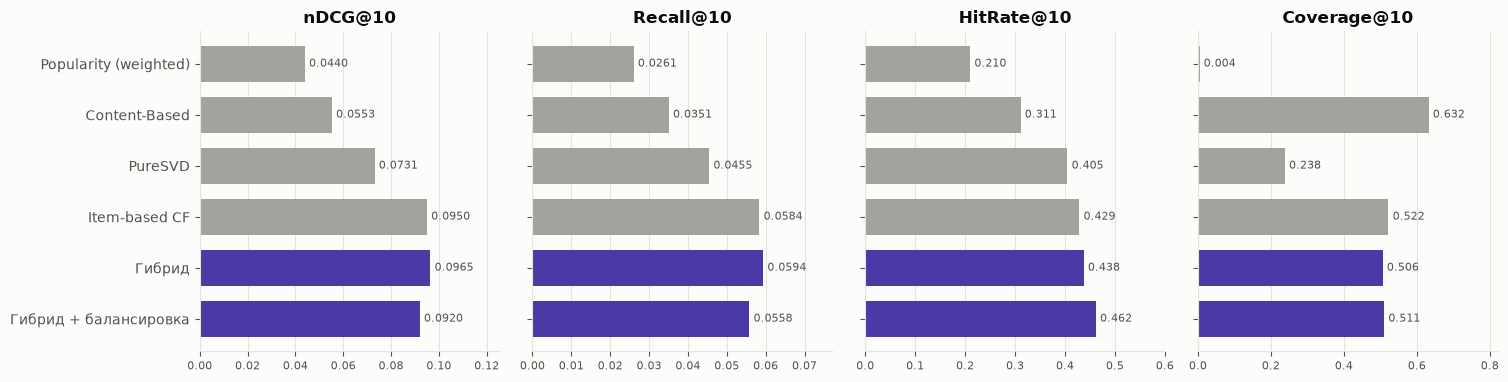

In [24]:
figure_models = [
    "Popularity (weighted)", "Content-Based", "PureSVD", "Item-based CF",
    "Гибрид", "Гибрид + балансировка",
]  # fmt: skip
fig = plots.plot_test_comparison(test_k10.loc[figure_models])
plots.save_figure(fig, "test_comparison");

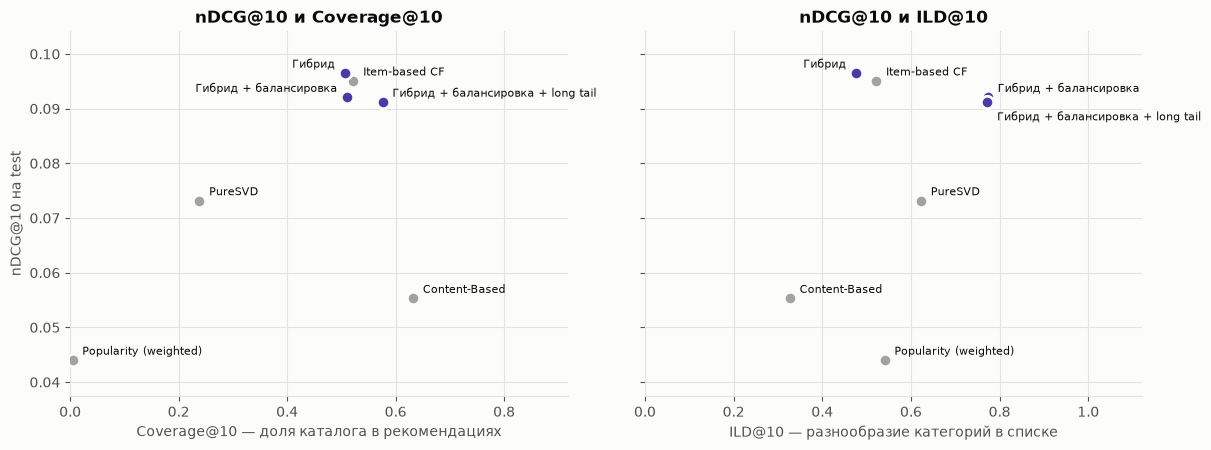

In [25]:
tradeoff_models = [*figure_models, "Гибрид + балансировка + long tail"]
fig = plots.plot_tradeoff(test_k10.loc[tradeoff_models])
plots.save_figure(fig, "accuracy_diversity");

Перенесённые модели на test воспроизводят домашнее задание: nDCG@10 Item-based CF 0.0950, PureSVD 0.0731, Content-Based 0.0553, Popularity 0.0440. Гибрид с подобранными весами превосходит лучшую отдельную модель при всех K: nDCG@10 0.0965 против 0.0950 (+1.6 %), Recall@10 0.0594 против 0.0584, HitRate@10 0.4376 против 0.4288; при K = 5 и K = 20 nDCG@K выше на 1.3 % и 1.5 %. Coverage@10 у гибрида немного ниже (0.506 против 0.522), разнообразие категорий в списке тоже ниже, чем у Item-based CF (ILD 0.476 против 0.522). Балансировка с q = 4 повышает ILD до 0.774 и HitRate@10 до 0.4619 (+5.6 % к гибриду), а nDCG@10 снижается на 4.7 % (до 0.0920), почти как на valid (−4.9 %). Квота long tail t = 3 увеличивает Coverage@10 с 0.511 до 0.576 и долю книг вне head с 0.235 до 0.361 при дополнительной потере 0.0008 nDCG@10. Без компоненты affinity метрики точности не хуже (nDCG@10 0.0966, HitRate@10 0.4393), а ILD выше (0.524 против 0.476): affinity дублирует сигнал о любимых категориях, который уже содержат Item-based CF и PureSVD, и сужает выдачу.

### 3.5. Сегменты активности пользователей

Сегменты по общему числу оценок пользователя (границы как в домашнем задании); сегмент используется только для группировки метрик и не входит в признаки моделей. Вертикальные отрезки на графике — 95 % доверительные интервалы.

n_users   ndcg  ndcg_ci  hit_rate  hit_rate_ci
model                 segment                                                
Popularity (weighted) <50          882 0.0283   0.0070    0.0918       0.0191
                      50–99      15387 0.0359   0.0017    0.1665       0.0059
                      100–149    32802 0.0466   0.0013    0.2258       0.0045
                      ≥150        4229 0.0564   0.0039    0.2734       0.0134
Content-Based         <50          882 0.0959   0.0111    0.3413       0.0313
                      50–99      15387 0.0562   0.0018    0.3095       0.0073
                      100–149    32802 0.0544   0.0012    0.3113       0.0050
                      ≥150        4229 0.0504   0.0031    0.3095       0.0139
Item-based CF         <50          882 0.1091   0.0121    0.3810       0.0321
                      50–99      15387 0.0913   0.0025    0.4078       0.0078
                      100–149    32802 0.0959   0.0017    0.4360       0.0054
                      ≥150        4229 0.0993   0.0047    0.4594       0.0150
Гибрид                <50          882 0.1094   0.0122    0.3855       0.0321
                      50–99      15387 0.0924   0.0025    0.4130       0.0078
                      100–149    32802 0.0976   0.0017    0.4470       0.0054
                      ≥150        4229 0.1000   0.0047    0.4649       0.0150
Гибрид + балансировка <50          882 0.1124   0.0120    0.4127       0.0325
                      50–99      15387 0.0870   0.0022    0.4305       0.0078
                      100–149    32802 0.0933   0.0015    0.4739       0.0054
                      ≥150        4229 0.0967   0.0042    0.4935       0.0151

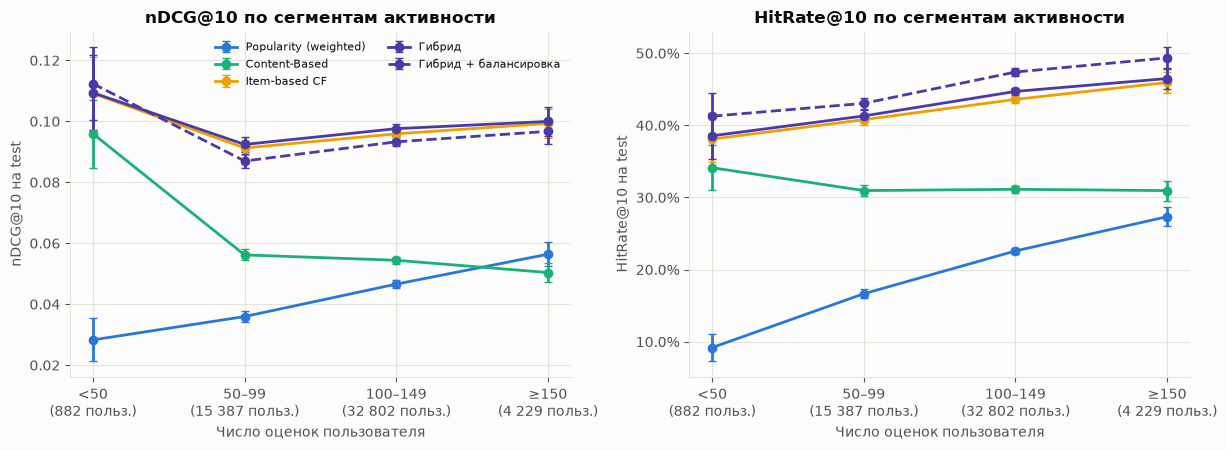

In [26]:
activity = evaluation.activity_segment(dataset.ratings)
segment_models = [
    "Popularity (weighted)", "Content-Based", "Item-based CF", "Гибрид", "Гибрид + балансировка",
]  # fmt: skip
test_segments = evaluation.segment_metrics(
    {name: test_top10[name] for name in segment_models}, test_set, activity
)
display(test_segments[["n_users", "ndcg", "ndcg_ci", "hit_rate", "hit_rate_ci"]])
fig = plots.plot_segment_metrics(test_segments)
plots.save_figure(fig, "segment_metrics");

Гибрид не уступает Item-based CF ни в одном сегменте активности, но разница меньше доверительных интервалов: nDCG@10 0.0924 против 0.0913 у пользователей с 50–99 оценками и 0.0976 против 0.0959 у пользователей со 100–149 оценками; полуширина интервала 0.0017–0.0025. Балансировка снижает nDCG@10 во всех сегментах, кроме самого малочисленного (< 50 оценок, 882 пользователя), а HitRate@10 повышает везде, на 1.8–2.9 п. п. Content-Based в сегменте < 50 оценок приближается к Item-based CF (0.0959 против 0.1091), а с ростом активности отстаёт сильнее (0.0504 против 0.0993 при ≥ 150 оценках). nDCG@10 Popularity растёт с активностью (0.0283 → 0.0564).

### 3.6. Новые пользователи: усечённая история

У 5 000 пользователей test история train усекается до первых 1, 3, 5 и 10 оценок; для каждой длины все модели обучаются заново. Точка «все» — те же пользователи с полной историей (модели раздела 3.4).

In [27]:
start = time.perf_counter()
test_cold_users = cold_start.sample_users(test_set.user_ids)
cold_histories = cold_start.evaluate_histories(
    outer.train, test_set, test_cold_users, dataset.books, book_tags, categories,
    {"Гибрид": {"weights": tuned_weights}, "Гибрид без affinity": {"weights": no_affinity}},
)  # fmt: skip
print(f"Обучение и оценка для {len(config.COLD_HISTORY_LENGTHS)} длин истории: "
      f"{time.perf_counter() - start:.0f} с")  # fmt: skip
cold_full_set = evaluation.subset(test_set, test_cold_users)
cold_full = evaluation.compare_recommendations(
    {
        name: evaluation.align_rows(test_top10[name], test_set, cold_full_set)
        for name in cold_histories.index.get_level_values("model").unique()
    },
    cold_full_set,
    ks=(10,),
).droplevel("k")
cold_table = pd.concat(
    [cold_histories, pd.concat({"все": cold_full}, names=["history"]).swaplevel()]
)
cold_table.reset_index().pivot_table(
    index="model", columns="history", values=["ndcg", "hit_rate", "coverage"], sort=False
)

Обучение и оценка для 4 длин истории: 368 с


ndcg                             hit_rate         \
history                    1      3      5     10    все        1      3   
model                                                                      
Popularity (weighted) 0.0449 0.0449 0.0449 0.0449 0.0450   0.2112 0.2112   
Content-Based         0.0268 0.0291 0.0308 0.0339 0.0562   0.1392 0.1594   
Item-based CF         0.0318 0.0372 0.0391 0.0450 0.0934   0.1752 0.2080   
Гибрид                0.0443 0.0465 0.0472 0.0493 0.0951   0.2130 0.2266   
Гибрид без affinity   0.0448 0.0468 0.0474 0.0494 0.0953   0.2244 0.2352   

                                           coverage                       \
history                    5     10    все        1      3      5     10   
model                                                                      
Popularity (weighted) 0.2112 0.2112 0.2114   0.0035 0.0035 0.0035 0.0035   
Content-Based         0.1742 0.1956 0.3140   0.6980 0.7138 0.6860 0.6254   
Item-based CF         0.2182 0.2430 0.4228   0.6666 0.6449 0.6038 0.5407   
Гибрид                0.2328 0.2448 0.4308   0.2348 0.2754 0.2772 0.2677   
Гибрид без affinity   0.2366 0.2474 0.4324   0.2419 0.2619 0.2518 0.2301   

                              
history                  все  
model                         
Popularity (weighted) 0.0035  
Content-Based         0.3953  
Item-based CF         0.3416  
Гибрид                0.3308  
Гибрид без affinity   0.3255

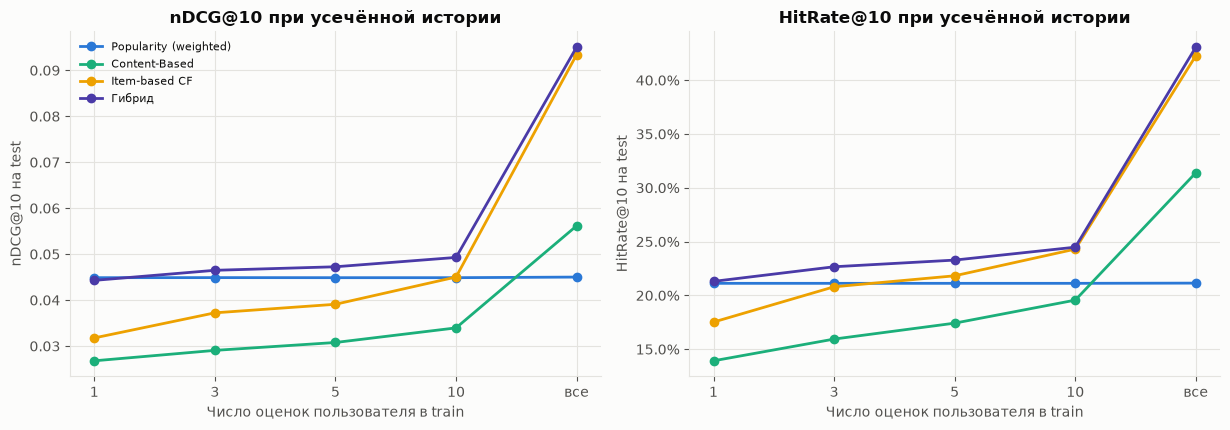

In [28]:
fig = plots.plot_cold_start(cold_table.drop(index="Гибрид без affinity", level="model"))
plots.save_figure(fig, "cold_start_users");

При усечённой истории гибрид (веса типа new) превосходит Item-based CF и Content-Based при любой длине истории, а Popularity — начиная с трёх оценок: nDCG@10 0.0465 против 0.0449 при трёх оценках и 0.0493 против 0.0449 при десяти. При одной оценке гибрид и Popularity практически равны (0.0443 против 0.0449), HitRate@10 у гибрида выше (0.2130 против 0.2112). Item-based CF достигает уровня Popularity только при 10 оценках (0.0450). Coverage@10 гибрида (0.23–0.28) в 67–79 раз выше, чем у Popularity (0.0035), но ниже, чем у Item-based CF и Content-Based (0.54–0.71): у новых пользователей основную часть веса получает popularity. Без affinity гибрид даёт ту же точность (nDCG@10 0.0448–0.0494): признак не помогает и при короткой истории.